In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (log_loss, brier_score_loss, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import silhouette_score
from scipy import stats

# Carga de datos

Se carga `bank.csv` y se renombran las columnas al español

In [ ]:
df_raw = pd.read_csv('CVS/bank.csv', sep=';')
nombres = {'age':'edad','job':'ocupacion','marital':'estado_civil',
    'education':'educacion','default':'mora','balance':'saldo',
    'housing':'hipoteca','loan':'prestamo','contact':'canal',
    'day':'dia','month':'mes','duration':'duracion(Segundos)',
    'campaign':'contactos_campana','pdays':'dias_previos',
    'previous':'contactos_previos','poutcome':'resultado_previo','y':'contrata'}
df = df_raw.rename(columns=nombres)
df.head()

,edad,ocupacion,estado_civil,educacion,mora,saldo,hipoteca,prestamo,canal,dia,mes,duracion(Segundos),contactos_campana,dias_previos,contactos_previos,resultado_previo,contrata
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


## 1(a) Tarea de aprendizaje

**Tarea de aprendizaje:** Corresponde a una clasificacion binaria supervisada.

**Unidad de observacion:** Cada fila representa un cliente contactado en una campana de marketing telefonico.

**Variable respuesta:** contrata — 1 si suscribio el deposito a plazo; 0 si no.

**Por que duracion no puede usarse:**
La duracion de la llamada solo se conoce *despues* de realizar la llamada al cliente. En produccion la prediccion
debe hacerse *antes* del contacto. Se excluye junto con id_cliente, pliegue y contrata.

## 1(b) Revision de los datos

In [ ]:
df_entrenamiento = pd.read_csv('clientes_entrenamiento.csv')
df_prueba  = pd.read_csv('clientes_prueba.csv')
print('tipos de variables')
print(df_entrenamiento.dtypes)
print(f'dimensiones: {df_entrenamiento.shape}')

tipos de variables
id_cliente            int64
edad                  int64
ocupacion            object
estado_civil         object
educacion            object
mora                 object
saldo                 int64
hipoteca             object
prestamo             object
canal                object
dia                   int64
mes                  object
duracion              int64
contactos_campana     int64
dias_previos          int64
contactos_previos     int64
resultado_previo     object
contrata              int64
pliegue               int64
dtype: object
dimensiones: (3617, 19)


In [ ]:
nulos = df_entrenamiento.isnull().sum()
print('valores nulos')
print(nulos[nulos>0] if nulos.any() else 'Sin valores nulos')
print('\n=== Categorias unknown ===')
columnas = df_entrenamiento.select_dtypes(include='object').columns.tolist()
for col in columnas:
    n = (df_entrenamiento[col]=='unknown').sum()
    if n>0: print(f'  {col}: {n} ({n/len(df_entrenamiento)*100:.1f}%)')

valores nulos
Sin valores nulos

=== Categorias unknown ===
  ocupacion: 32 (0.9%)
  educacion: 161 (4.5%)
  canal: 1064 (29.4%)
  resultado_previo: 2972 (82.2%)


In [ ]:
cols_dup = [c for c in df_entrenamiento.columns if c not in ['id_cliente','pliegue']]
print(f'Duplicados: {df_entrenamiento.duplicated(subset=cols_dup).sum()}')

Duplicados: 0


In [ ]:
vc = df_entrenamiento['contrata'].value_counts()
print(f'balance de clases:')
print(f'no contrata (0): {vc[0]} ({vc[0]/len(df_entrenamiento)*100:.1f}%)')
print(f'contrata    (1): {vc[1]} ({vc[1]/len(df_entrenamiento)*100:.1f}%)')
print(f'exactitud clase mayoritaria: {vc[0]/len(df_entrenamiento)*100:.2f}%')


balance de clases:
no contrata (0): 3200 (88.5%)
contrata    (1): 417 (11.5%)
exactitud clase mayoritaria: 88.47%


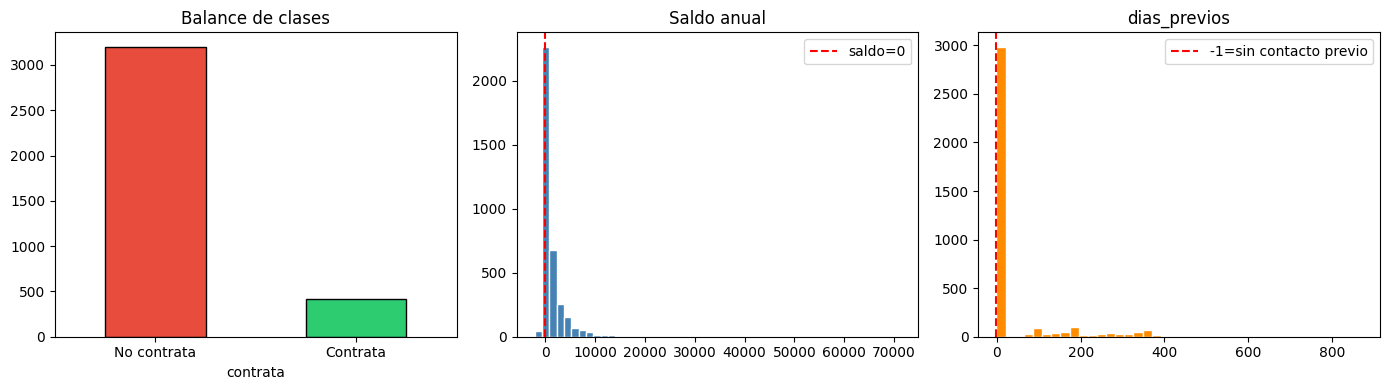

Saldo negativo: 284 registros
dias_previos==-1: 2972 (82.2%)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
df_entrenamiento['contrata'].value_counts().plot(kind='bar', ax=axes[0], color=['#e74c3c','#2ecc71'], edgecolor='black')

#Grafico balance de clases
axes[0].set_title('Balance de clases')
axes[0].set_xticklabels(['No contrata','Contrata'], rotation=0)

#Grafico de saldo anual
axes[1].hist(df_entrenamiento['saldo'], bins=50, color='steelblue', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', label='saldo=0')
axes[1].set_title('Saldo anual'); axes[1].legend()

#Grafico de dias previos
axes[2].hist(df_entrenamiento['dias_previos'], bins=40, color='darkorange', edgecolor='white')
axes[2].axvline(-1, color='red', linestyle='--', label='-1=sin contacto previo')
axes[2].set_title('dias_previos'); axes[2].legend()

plt.tight_layout(); plt.show()
print(f'Saldo negativo: {(df_entrenamiento["saldo"]<0).sum()} registros')
print(f'dias_previos==-1: {(df_entrenamiento["dias_previos"]==-1).sum()} ({(df_entrenamiento["dias_previos"]==-1).mean()*100:.1f}%)')

responder:

## 1(c) Ingenieria de variables y preprocesamiento

In [ ]:
#Transofmramos categoricas mediante one-hot
def preparar_X(df, categoricas_cols, scaler=None, ohe=None, fit=True):
    X_categoricas = df[categoricas_cols].values
    if fit:
        ohe    = OneHotEncoder(sparse_output=False, handle_unknown='ignore').fit(X_categoricas)
    X_categoricas_transformadas = ohe.transform(X_categoricas)
    return np.hstack([ X_categoricas_transformadas]), scaler, ohe

#Se crean nuevas columnas a partir de dias previos y contactos_previos
def creacion_columnas(df):
    d = df.copy()

    d['contactado_antes'] = (d['dias_previos'] != -1).astype(int)
    d['log_contactos_previos'] = np.log1p(d['contactos_previos'])
    d['dias_previos'] = d['dias_previos'].replace(-1, 0)
    return d
# excluimos columnas que no se van a usar para entrenar el modelo
EXCLUIR = ['id_cliente', 'pliegue', 'duracion', 'contrata']
df_campos_agregados = creacion_columnas(df_entrenamiento)
columnas_transformadas = [c for c in df_campos_agregados.columns if c not in EXCLUIR]
NUM_COLS = df_campos_agregados[columnas_transformadas].select_dtypes(include=['int64','float64']).columns.tolist()
CAT_COLS = df_campos_agregados[columnas_transformadas].select_dtypes(include='object').columns.tolist()
print(f'Features numericas ({len(NUM_COLS)}): {NUM_COLS}')
print(f'Features categoricas ({len(CAT_COLS)}): {CAT_COLS}')

Features numericas (8): ['edad', 'saldo', 'dia', 'contactos_campana', 'dias_previos', 'contactos_previos', 'contactado_antes', 'log_contactos_previos']
Features categoricas (9): ['ocupacion', 'estado_civil', 'educacion', 'mora', 'hipoteca', 'prestamo', 'canal', 'mes', 'resultado_previo']


In [ ]:
df_campos_agregados = creacion_columnas(df_entrenamiento)
print('contactado_antes value_counts:')
print(df_campos_agregados['contactado_antes'].value_counts())
print('\nlog_contactos_previos stats:')
print(df_campos_agregados['log_contactos_previos'].describe())
print('\ndias_previos tras reemplazo (primeros 5):')
print(df_campos_agregados['dias_previos'].head())

contactado_antes value_counts:
contactado_antes
0    2972
1     645
Name: count, dtype: int64

log_contactos_previos stats:
count    3617.000000
mean        0.215091
std         0.510888
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         3.218876
Name: log_contactos_previos, dtype: float64

dias_previos tras reemplazo (primeros 5):
0    183
1      0
2      0
3      0
4      0
Name: dias_previos, dtype: int64


In [ ]:
df_campos_agregados

,id_cliente,edad,ocupacion,estado_civil,educacion,mora,saldo,hipoteca,prestamo,canal,...,mes,duracion,contactos_campana,dias_previos,contactos_previos,resultado_previo,contrata,pliegue,contactado_antes,log_contactos_previos
0,1876,30,blue-collar,single,secondary,no,180,no,no,cellular,...,jul,203,1,183,2,failure,0,2,1,1.098612
1,506,31,unemployed,married,secondary,no,296,yes,no,unknown,...,may,378,3,0,0,unknown,0,1,0,0.000000
2,4423,37,services,divorced,primary,no,260,yes,no,cellular,...,apr,446,2,0,0,unknown,0,4,0,0.000000
3,3731,43,technician,married,secondary,no,3285,yes,no,unknown,...,may,1721,2,0,0,unknown,1,4,0,0.000000
4,3583,36,management,married,tertiary,no,0,yes,no,unknown,...,may,145,2,0,0,unknown,0,1,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3612,583,31,admin.,married,secondary,no,236,yes,yes,telephone,...,may,211,3,0,0,unknown,0,3,0,0.000000
3613,2447,30,blue-collar,married,secondary,no,-28,yes,no,cellular,...,may,284,2,371,1,failure,0,3,1,0.693147
3614,885,48,management,married,primary,no,606,no,no,cellular,...,mar,77,6,0,0,unknown,0,1,0,0.000000
3615,655,58,retired,married,secondary,no,225,no,no,cellular,...,aug,122,6,0,0,unknown,0,1,0,0.000000


responder:

## 2(a) Regresion logistica: todas las columnas vs seleccion F-ANOVA

## 2(b) Comparacion de modelos OOF

## 2(c) Interpretacion de resultados

## 3(a) Seleccion de umbral optimo

## 3(b) Evaluacion en conjunto de prueba 

## 4(a) PCA

## 4(b) K-means

# 5(a) Deteccion de anomalias 

## 5(b) Interpretacion 